# Questão 8 - Diagnóstico médico com Redes Bayesianas

## 1. Domínio

O domínio escolhido é o diagnóstico de gripe (influenza) em um atendimento de triagem. A doença principal é a gripe. O resfriado comum entra na rede como uma segunda doença, porque ele também causa tosse e costuma ser confundido com gripe.

O sistema recebe o que se sabe sobre o paciente (sintomas e fatores de risco) e devolve a probabilidade de ele estar com gripe. Nem tudo precisa ser informado: a rede trabalha com as evidências que tiver.

A rede foi implementada em Python com a biblioteca pgmpy. Os valores usados são didáticos e o sistema não substitui uma avaliação médica.

In [1]:
import itertools
import logging
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.models import DiscreteBayesianNetwork

logging.getLogger("pgmpy").setLevel(logging.ERROR)

## 2. Variáveis

Todas as variáveis têm dois valores: sim ou nao.

**Surto:** há um surto de gripe na região no momento (fator de risco).

**Vacinado:** o paciente tomou a vacina da gripe neste ano (fator de proteção).

**Gripe:** o paciente está com gripe. É a variável que se quer diagnosticar.

**Resfriado:** o paciente está com resfriado comum.

**Febre, DorMuscular, Tosse, Coriza:** sintomas observáveis.

## 3. Estrutura da rede

As setas vão da causa para o efeito.

**Surto -> Gripe:** com mais vírus circulando, a chance de pegar gripe aumenta.

**Vacinado -> Gripe:** a vacina diminui a chance de pegar gripe.

**Gripe -> Febre e Gripe -> DorMuscular:** febre e dor no corpo são sintomas típicos da gripe e raros no resfriado.

**Gripe -> Tosse e Resfriado -> Tosse:** as duas doenças causam tosse. Por isso Tosse tem dois pais.

**Resfriado -> Coriza:** coriza é o sintoma mais marcante do resfriado.

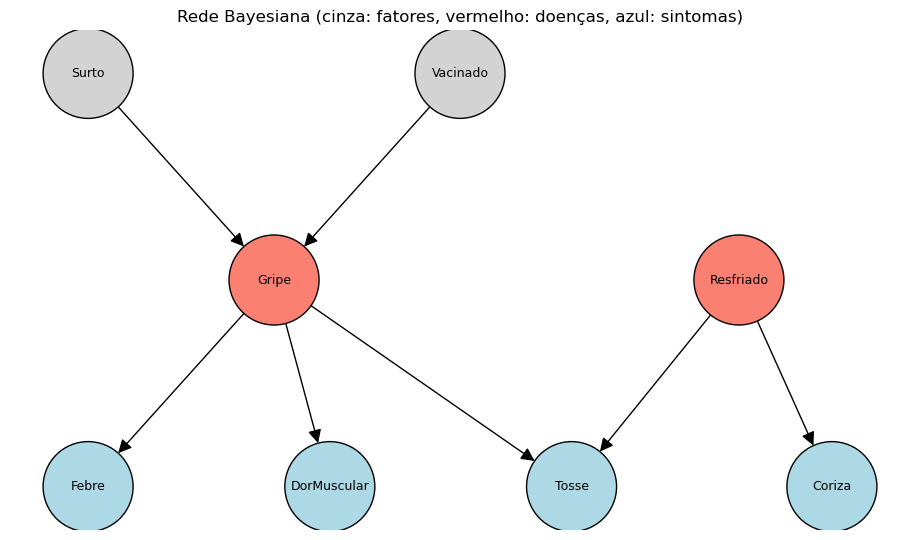

In [2]:
arestas = [
    ("Surto", "Gripe"), ("Vacinado", "Gripe"),
    ("Gripe", "Febre"), ("Gripe", "DorMuscular"), ("Gripe", "Tosse"),
    ("Resfriado", "Tosse"), ("Resfriado", "Coriza"),
]
rede = DiscreteBayesianNetwork(arestas)

pos = {
    "Surto": (0, 2), "Vacinado": (2, 2), "Gripe": (1, 1), "Resfriado": (3.5, 1),
    "Febre": (0, 0), "DorMuscular": (1.3, 0), "Tosse": (2.6, 0), "Coriza": (4, 0),
}
cores = ["lightgray" if n in ("Surto", "Vacinado") else "salmon" if n in ("Gripe", "Resfriado") else "lightblue" for n in rede.nodes()]

plt.figure(figsize=(9, 5))
nx.draw(nx.DiGraph(arestas), pos, nodelist=list(rede.nodes()), node_color=cores, with_labels=True,
        node_size=4200, font_size=9, edgecolors="black", arrowsize=20)
plt.title("Rede Bayesiana (cinza: fatores, vermelho: doenças, azul: sintomas)")
plt.show()

## 4. Tabelas de probabilidades condicionais

As probabilidades foram definidas de forma plausível para fins didáticos, seguindo o que se sabe de forma geral sobre as duas doenças.

**Surto (0,20):** os surtos de gripe se concentram em poucos meses do ano.

**Vacinado (0,40):** valor próximo de uma cobertura vacinal mediana na população geral.

**Resfriado (0,15):** o resfriado é comum e independe dos outros fatores da rede.

**Gripe:** sem surto e sem vacina, 6 % dos pacientes da triagem têm gripe. O surto multiplica esse valor por cerca de seis. A vacina reduz o risco em torno de 65 %, que é uma eficácia razoável para a vacina da gripe.

**Febre:** aparece em 85 % dos casos de gripe. Sem gripe, 7 % dos pacientes têm febre por outros motivos.

**DorMuscular:** aparece em 70 % dos casos de gripe e em 8 % dos pacientes sem gripe.

**Tosse:** 80 % com gripe, 55 % com resfriado, 90 % com as duas e 8 % sem nenhuma.

**Coriza:** 85 % com resfriado e 10 % sem resfriado (alergias, por exemplo).

In [3]:
SN = ["sim", "nao"]


def cpd(variavel, p_sim, pais=None):
    valores = [p_sim, [1 - p for p in p_sim]]
    nomes = {v: SN for v in [variavel] + (pais or [])}
    return TabularCPD(variavel, 2, valores, evidence=pais, evidence_card=[2] * len(pais) if pais else None, state_names=nomes)


# colunas na ordem (sim,sim), (sim,nao), (nao,sim), (nao,nao) dos pais
cpds = [
    cpd("Surto", [0.20]),
    cpd("Vacinado", [0.40]),
    cpd("Resfriado", [0.15]),
    cpd("Gripe", [0.12, 0.35, 0.02, 0.06], ["Surto", "Vacinado"]),
    cpd("Febre", [0.85, 0.07], ["Gripe"]),
    cpd("DorMuscular", [0.70, 0.08], ["Gripe"]),
    cpd("Tosse", [0.90, 0.80, 0.55, 0.08], ["Gripe", "Resfriado"]),
    cpd("Coriza", [0.85, 0.10], ["Resfriado"]),
]
rede.add_cpds(*cpds)
print("Modelo válido:", rede.check_model())

Modelo válido: True


In [4]:
for tabela in cpds:
    print(tabela, "\n")

+------------+-----+
| Surto(sim) | 0.2 |
+------------+-----+
| Surto(nao) | 0.8 |
+------------+-----+ 

+---------------+-----+
| Vacinado(sim) | 0.4 |
+---------------+-----+
| Vacinado(nao) | 0.6 |
+---------------+-----+ 

+----------------+------+
| Resfriado(sim) | 0.15 |
+----------------+------+
| Resfriado(nao) | 0.85 |
+----------------+------+ 

+------------+---------------+---------------+---------------+---------------+
| Surto      | Surto(sim)    | Surto(sim)    | Surto(nao)    | Surto(nao)    |
+------------+---------------+---------------+---------------+---------------+
| Vacinado   | Vacinado(sim) | Vacinado(nao) | Vacinado(sim) | Vacinado(nao) |
+------------+---------------+---------------+---------------+---------------+
| Gripe(sim) | 0.12          | 0.35          | 0.02          | 0.06          |
+------------+---------------+---------------+---------------+---------------+
| Gripe(nao) | 0.88          | 0.65          | 0.98          | 0.94          |
+------

## 5. Hipóteses e independências condicionais

**Hipóteses da modelagem:**

Os sintomas dependem só das doenças. Dado que se sabe se o paciente tem gripe, febre e dor muscular não trazem informação uma sobre a outra.

Gripe e resfriado são independentes antes de se observar algum sintoma.

Surto e vacinação são independentes entre si.

A vacina e o surto só afetam os sintomas por meio da gripe.

**Independências representadas na rede:** cada variável é independente das suas não descendentes quando os pais são conhecidos. A lista abaixo é gerada pela própria biblioteca.

In [5]:
for no in rede.nodes():
    ind = rede.local_independencies(no)
    if ind.get_assertions():
        print(ind)

(Surto ⟂ Coriza, Resfriado, Vacinado)
(Gripe ⟂ Coriza, Resfriado | Surto, Vacinado)
(Vacinado ⟂ Coriza, Resfriado, Surto)
(Febre ⟂ Coriza, DorMuscular, Resfriado, Surto, Tosse, Vacinado | Gripe)
(DorMuscular ⟂ Coriza, Febre, Resfriado, Surto, Tosse, Vacinado | Gripe)
(Tosse ⟂ Coriza, DorMuscular, Febre, Surto, Vacinado | Gripe, Resfriado)
(Resfriado ⟂ DorMuscular, Febre, Gripe, Surto, Vacinado)
(Coriza ⟂ DorMuscular, Febre, Gripe, Surto, Tosse, Vacinado | Resfriado)


Alguns casos conferidos por d-separação:

In [6]:
testes = [
    ("Febre", "DorMuscular", []),
    ("Febre", "DorMuscular", ["Gripe"]),
    ("Surto", "Febre", []),
    ("Surto", "Febre", ["Gripe"]),
    ("Gripe", "Resfriado", []),
    ("Gripe", "Resfriado", ["Tosse"]),
]
pd.DataFrame(
    [
        {"X": a, "Y": b, "dado": ", ".join(z) or "nada", "independentes": not rede.is_dconnected(a, b, observed=z)}
        for a, b, z in testes
    ]
)

,X,Y,dado,independentes
0,Febre,DorMuscular,nada,False
1,Febre,DorMuscular,Gripe,True
2,Surto,Febre,nada,False
3,Surto,Febre,Gripe,True
4,Gripe,Resfriado,nada,True
5,Gripe,Resfriado,Tosse,False


Febre e DorMuscular são dependentes quando nada é observado, porque as duas indicam gripe. Ficam independentes quando Gripe é conhecida.

Gripe e Resfriado são independentes no início, mas passam a ser dependentes quando a Tosse é observada. Esse efeito aparece no experimento 3.

## 6. Inferência

A inferência usa o algoritmo de eliminação de variáveis, que calcula a probabilidade exata.

In [7]:
inferencia = VariableElimination(rede)


def prob(variavel="Gripe", evidencias=None, **extra):
    evidencias = evidencias or {}
    if variavel in evidencias:
        return float(evidencias[variavel] == "sim")
    resultado = inferencia.query([variavel], evidence=evidencias, show_progress=False, **extra)
    return float(resultado.get_value(**{variavel: "sim"}))


def texto(evidencias):
    return ", ".join(f"{k}={v}" for k, v in evidencias.items()) or "nenhuma"

**Probabilidades a priori**

Sem nenhuma evidência, a rede já tem uma probabilidade para cada variável.

In [8]:
priori = pd.Series({v: prob(v) for v in rede.nodes()}, name="P(sim)").round(4)
priori.to_frame()

,P(sim)
Surto,0.2000
Gripe,0.0868
Vacinado,0.4000
Febre,0.1377
DorMuscular,0.1338
Tosse,0.2082
Resfriado,0.1500
Coriza,0.2125


**Conferência manual**

Para confirmar que a inferência está correta, P(Gripe | Febre = sim) é calculada pelo teorema de Bayes e depois por enumeração de toda a distribuição conjunta.

In [9]:
p_g = sum(
    ps * pv * pg
    for (ps, pv), pg in zip(itertools.product([0.20, 0.80], [0.40, 0.60]), [0.12, 0.35, 0.02, 0.06])
)
p_febre = 0.85 * p_g + 0.07 * (1 - p_g)
print(f"P(Gripe) = {p_g:.4f}")
print(f"P(Febre) = 0,85 x {p_g:.4f} + 0,07 x {1 - p_g:.4f} = {p_febre:.4f}")
print(f"Bayes:      P(Gripe | Febre) = 0,85 x {p_g:.4f} / {p_febre:.4f} = {0.85 * p_g / p_febre:.4f}")


def conjunta(atribuicao):
    p = 1.0
    for t in rede.get_cpds():
        p *= t.get_value(**{v: atribuicao[v] for v in t.variables})
    return p


nos = list(rede.nodes())
num = den = 0.0
for valores in itertools.product(SN, repeat=len(nos)):
    a = dict(zip(nos, valores))
    if a["Febre"] == "sim":
        p = conjunta(a)
        den += p
        num += p if a["Gripe"] == "sim" else 0
print(f"Enumeração: P(Gripe | Febre) = {num / den:.4f}")
print(f"pgmpy:      P(Gripe | Febre) = {prob('Gripe', {'Febre': 'sim'}):.4f}")

P(Gripe) = 0.0868
P(Febre) = 0,85 x 0.0868 + 0,07 x 0.9132 = 0.1377
Bayes:      P(Gripe | Febre) = 0,85 x 0.0868 / 0.1377 = 0.5358
Enumeração: P(Gripe | Febre) = 0.5358
pgmpy:      P(Gripe | Febre) = 0.5358


## 7. Experimentos

**Experimento 1: diagnóstico a partir dos sintomas**

O paciente chega com febre e tosse. Não se sabe nada sobre os outros sintomas nem sobre os fatores de risco.

In [10]:
ev1 = {"Febre": "sim", "Tosse": "sim"}
pd.DataFrame(
    {
        "a priori": [prob("Gripe"), prob("Resfriado")],
        "a posteriori": [prob("Gripe", ev1), prob("Resfriado", ev1)],
    },
    index=["Gripe", "Resfriado"],
).round(4)

,a priori,a posteriori
Gripe,0.0868,0.8621
Resfriado,0.1500,0.2184


Evidências: Febre = sim e Tosse = sim. A probabilidade de gripe sobe de cerca de 9 % para mais de 80 %. A de resfriado sobe pouco, de 15 % para cerca de 22 %: a tosse aponta para resfriado, mas a febre faz a gripe explicar melhor o quadro.

**Experimento 2: atualização com novas evidências**

As evidências são informadas uma de cada vez e a probabilidade de gripe é recalculada a cada passo.

In [11]:
def sequencia(passos):
    evid, linhas = {}, [{"evidência acrescentada": "nenhuma (a priori)", "P(Gripe)": prob("Gripe")}]
    for var, val in passos:
        evid[var] = val
        linhas.append({"evidência acrescentada": f"{var} = {val}", "P(Gripe)": prob("Gripe", evid)})
    df = pd.DataFrame(linhas)
    df["variação"] = df["P(Gripe)"].diff().fillna(0)
    return df.round(4)


seq = sequencia([("Febre", "sim"), ("Tosse", "sim"), ("DorMuscular", "sim"), ("Surto", "sim"), ("Vacinado", "sim")])
seq

,evidência acrescentada,P(Gripe),variação
0,nenhuma (a priori),0.0868,0.0000
1,Febre = sim,0.5358,0.4490
2,Tosse = sim,0.8621,0.3263
3,DorMuscular = sim,0.9820,0.1200
4,Surto = sim,0.9950,0.0130
5,Vacinado = sim,0.9874,-0.0076


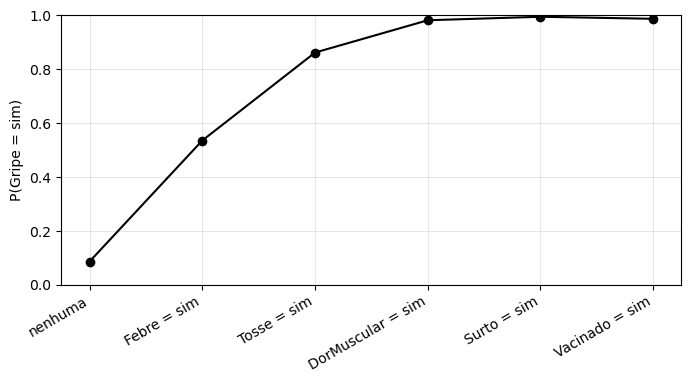

In [12]:
plt.figure(figsize=(8, 3.5))
plt.plot(range(len(seq)), seq["P(Gripe)"], marker="o", color="black")
plt.xticks(range(len(seq)), [t.replace(" (a priori)", "") for t in seq["evidência acrescentada"]], rotation=30, ha="right")
plt.ylabel("P(Gripe = sim)")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.show()

A febre é a evidência que mais muda o diagnóstico, porque é comum na gripe e rara sem ela. Tosse e dor muscular reforçam. Saber que há um surto aumenta ainda mais a probabilidade. A vacina puxa o valor para baixo, mas pouco: com três sintomas típicos presentes, os sintomas pesam mais que o fator de proteção.

**Experimento 3: comparação entre conjuntos de evidências**

In [13]:
conjuntos = [
    {"Tosse": "sim"},
    {"Tosse": "sim", "Coriza": "sim"},
    {"Tosse": "sim", "Resfriado": "sim"},
    {"Tosse": "sim", "Febre": "sim", "Coriza": "sim"},
    {"Febre": "sim", "Tosse": "nao", "DorMuscular": "nao"},
    {"Febre": "nao", "Tosse": "nao", "DorMuscular": "nao"},
    {"Surto": "sim", "Vacinado": "nao"},
    {"Surto": "sim", "Vacinado": "sim"},
]
pd.DataFrame(
    [{"evidências": texto(e), "P(Gripe)": prob("Gripe", e), "P(Resfriado)": prob("Resfriado", e)} for e in conjuntos]
).round(4)

,evidências,P(Gripe),P(Resfriado)
0,Tosse=sim,0.3398,0.4182
1,"Tosse=sim, Coriza=sim",0.1842,0.8593
2,"Tosse=sim, Resfriado=sim",0.1346,1.0000
3,"Tosse=sim, Febre=sim, Coriza=sim",0.7328,0.7037
4,"Febre=sim, Tosse=nao, DorMuscular=nao",0.0758,0.0796
5,"Febre=nao, Tosse=nao, DorMuscular=nao",0.0011,0.0795
6,"Surto=sim, Vacinado=nao",0.3500,0.1500
7,"Surto=sim, Vacinado=sim",0.1200,0.1500


Só com tosse, gripe e resfriado ficam como hipóteses possíveis. Quando a coriza aparece, a probabilidade de resfriado sobe e a de gripe cai, mesmo sem existir seta entre Coriza e Gripe. O resfriado passa a explicar a tosse e a gripe deixa de ser necessária. Esse efeito é chamado de explicação alternativa (explaining away) e um sistema de regras simples não consegue reproduzir.

A falta de sintomas também é evidência. Com febre, mas sem tosse e sem dor muscular, a probabilidade de gripe fica bem menor do que só com febre.

As duas últimas linhas usam apenas fatores de risco, sem nenhum sintoma. É uma inferência no sentido causa para efeito (preditiva), enquanto as anteriores vão do efeito para a causa (diagnóstica).

**Experimento 4: evidência incerta**

Às vezes a evidência não é segura. Suponha que o paciente diga que "acha que teve febre", mas não mediu. Isso é tratado como evidência virtual: em vez de fixar Febre = sim, informa-se que o relato é quatro vezes mais provável se a febre existiu (0,8 contra 0,2).

In [14]:
relato = TabularCPD("Febre", 2, [[0.8], [0.2]], state_names={"Febre": SN})
pd.DataFrame(
    {
        "P(Gripe)": [
            prob("Gripe", {"Tosse": "sim"}),
            prob("Gripe", {"Tosse": "sim"}, virtual_evidence=[relato]),
            prob("Gripe", {"Tosse": "sim", "Febre": "sim"}),
        ]
    },
    index=["tosse, sem informação de febre", "tosse e febre relatada (incerta)", "tosse e febre medida (certa)"],
).round(4)

,P(Gripe)
"tosse, sem informação de febre",0.3398
tosse e febre relatada (incerta),0.6016
tosse e febre medida (certa),0.8621


O resultado com a evidência incerta fica entre os outros dois. Quanto mais confiável o relato, mais perto ele chega do valor com febre confirmada.

## 8. Arquivo do modelo

A rede é salva no formato BIF, que pode ser aberto em outras ferramentas de redes bayesianas e carregado de novo pelo pgmpy.

In [15]:
rede.save("rede_gripe.bif", filetype="bif")
recarregada = DiscreteBayesianNetwork.load("rede_gripe.bif", filetype="bif")
print("Nós:", sorted(recarregada.nodes()))

Nós: ['Coriza', 'DorMuscular', 'Febre', 'Gripe', 'Resfriado', 'Surto', 'Tosse', 'Vacinado']


## 9. Discussão

**Como a rede representa a incerteza**

A incerteza está nas tabelas de probabilidade. Nenhuma relação é tratada como certa: gripe não causa febre sempre, causa em 85 % dos casos. A estrutura do grafo diz quais variáveis influenciam quais, e as tabelas dizem com que força. Juntas, elas definem a distribuição conjunta das oito variáveis usando 17 parâmetros, em vez dos 255 que seriam necessários sem as independências.

**Influência de cada evidência**

A febre foi a evidência mais forte, seguida da dor muscular e da tosse. A tosse sozinha diz pouco porque tem duas causas possíveis. A coriza diminui a chance de gripe de forma indireta, ao fortalecer a hipótese de resfriado. Os fatores de risco mudam a probabilidade antes dos sintomas, mas perdem importância quando vários sintomas já foram observados.

**Vantagens em relação a sistemas só de regras**

Uma regra do tipo "se febre e tosse então gripe" dá uma resposta fixa. A rede dá uma probabilidade, que muda de acordo com o conjunto de evidências.

A rede funciona com evidências incompletas. Uma regra que exige três sintomas não dispara se só dois forem informados.

A mesma rede responde perguntas nos dois sentidos, da causa para o efeito e do efeito para a causa.

A rede trata corretamente evidências que competem entre si, como no caso da coriza.

Uma evidência nova pode diminuir uma conclusão anterior. Em regras clássicas, uma conclusão tirada não é desfeita.

**Limitações**

As probabilidades foram definidas de forma plausível e não vieram de dados reais.

Todas as variáveis são binárias. A febre, por exemplo, poderia ter níveis.

Só duas doenças foram modeladas. Dengue e covid-19 têm sintomas parecidos e ficaram de fora.

A rede não considera idade, doenças anteriores nem o tempo de duração dos sintomas.

Assume-se que os sintomas são independentes quando a doença é conhecida, o que nem sempre é verdade.

**Melhorias possíveis**

Aprender as probabilidades a partir de uma base de atendimentos reais.

Incluir outras doenças respiratórias e exames, como o teste rápido.

Usar variáveis com mais de dois valores e incluir a idade do paciente.

Acrescentar um nó de decisão e de utilidade para recomendar a conduta (observar, testar ou tratar).